# Change in land area per dry-spell class, 30–60°N: CMIP6 models (2035–2049 minus 2021–2034)

Same figure as `cesm2_ensmean_land_dry_consect_b&w_fut.ipynb`, with CESM2 replaced by the CMIP6 multi-model ensemble.

- **Data:** the ssp370 ensemble files in `30-60N/ensemble` (NCO or Python version). Both periods lie within ssp370, so no historical files are needed. Land is `sftlf > 0`, with cos(lat) area weights. BCC-CSM2-MR has no sftlf file and uses the `FALLBACK_MASK_MODEL` mask.
- **Per member (as in the CESM2 notebook):** for each year, the share of land area in each class of longest dry spell. These shares are averaged over each period, and the change is late minus early (percentage points).
- **One member per model:** only the first member of each model is used (`MEMBERS_PER_MODEL = 1`; lowest r, then i, p, f, e.g. r1i1p1f1, or r2i1p1f1 if r1 does not exist), the same member as in the historical notebooks. The box per class shows the spread of the models, one value per model. Whiskers reach the min/max model, the line is the median, the diamond and the number are the CMIP6 mean (mean of the model values).
- **Table:** the change per model and class, plus the CMIP6 mean, saved as csv.

In [1]:
import os
import re

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings(action='ignore')

In [2]:
# ── settings ─────────────────────────────────────────────────────────────────
ENS_DIR    = '/home/jwille/xenon_data/NextGEMS/dry_spells/CMIP6/30-60N/ensemble'   # dry_spell_<model>_ssp370_ensemble_native.nc
SFTLF_DIR  = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
EXPERIMENT = 'ssp370'
EARLY      = (2021, 2034)
LATE       = (2035, 2049)

FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'   # mask used for models without an sftlf file (BCC-CSM2-MR)
EXCLUDE_MODELS      = []                # e.g. ['BCC-CSM2-MR']
MEMBERS_PER_MODEL   = 1                 # first N members of each model (sorted r, i, p, f); None = all members

bin_edges  = [0, 10, 20, 30, 50, np.inf]
bin_labels = ['0–10', '10–20', '20–30', '30–50', '50+']
YLIM       = None                       # None = automatic (symmetric, room for the labels); CESM2 figure used (-4.5, 4.5)

OUT_FIG   = '/home/jwille/images/global_paper/mid_lat_land_cmip6_ens_barplot_dry_spell_change.pdf'
OUT_TABLE = '/home/jwille/images/global_paper/mid_lat_land_cmip6_dry_spell_change_per_model.csv'

In [3]:
def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def nearest_regrid(src, lat, lon):
    """Nearest-neighbour match of a lat/lon field to the given lat/lon (lon periodic).
    Identical grids give exactly the original values."""
    ilat = np.abs(src.lat.values[:, None] - np.asarray(lat)[None, :]).argmin(axis=0)
    dlon = (src.lon.values[:, None] - np.asarray(lon)[None, :] + 180) % 360 - 180
    ilon = np.abs(dlon).argmin(axis=0)
    return xr.DataArray(src.values[np.ix_(ilat, ilon)], dims=('lat', 'lon'), coords={'lat': lat, 'lon': lon})


def find_sftlf(model):
    """sftlf file of a model: historical preferred, else any experiment; None if there is none."""
    pat = re.compile(rf'^sftlf_fx_{re.escape(model)}_(?P<exp>[^_]+)_(?P<mem>[^_]+)_[^_]+\.nc$')
    cands = [(m['exp'] != 'historical', member_sort_key(m['mem']), f)
             for f in os.listdir(SFTLF_DIR) if (m := pat.match(f))]
    return os.path.join(SFTLF_DIR, sorted(cands)[0][2]) if cands else None


def land_mask(model, lat, lon):
    path = find_sftlf(model)
    src = xr.open_dataset(path or find_sftlf(FALLBACK_MASK_MODEL))['sftlf'].load()
    return (nearest_regrid(src, lat, lon) > 0).values, (os.path.basename(path) if path else f'{FALLBACK_MASK_MODEL} (fallback)')


def member_labels(ds):
    """Member names of an ensemble file: 'member_labels' attribute (NCO version, member = 1..N)
    or the member coordinate itself (Python version, member = 'r1i1p1f1', ...)."""
    lab = ds['member'].attrs.get('member_labels') or ds.attrs.get('member_labels')
    return lab.split(',') if lab else [str(m) for m in ds['member'].values]


def area_fractions(da, land, w2d):
    """da (member, year, lat, lon). Returns (member, year, bin): cos(lat)-weighted share (%) of the
    land area in each dry-spell class, NaN points left out (same as the CESM2 notebook)."""
    v = da.values[..., land]                                  # (member, year, land points)
    w = np.where(np.isfinite(v), w2d[land], 0.0)
    total = w.sum(axis=-1)
    fr = np.stack([(w * ((v >= lo) & (v < hi))).sum(axis=-1) for lo, hi in zip(bin_edges[:-1], bin_edges[1:])], axis=-1)
    with np.errstate(invalid='ignore', divide='ignore'):
        return 100.0 * fr / total[..., None]

In [4]:
# ── change per member, then per model (mean over the members used; with MEMBERS_PER_MODEL = 1 the first member) ──
ENS = re.compile(r'^dry_spell_(?P<model>[^_]+)_(?P<exp>[^_]+)_ensemble_[^_]+\.nc$')
ens_files = sorted(((m['model'], f) for f in os.listdir(ENS_DIR)
                    if (m := ENS.match(f)) and m['exp'] == EXPERIMENT and m['model'] not in EXCLUDE_MODELS),
                   key=lambda mf: mf[0].lower())

model_change = {}    # model -> (n_bins,) mean change over the members used
member_change = {}   # model -> (n_members, n_bins)
for model, fname in ens_files:
    ens = xr.open_dataset(os.path.join(ENS_DIR, fname))
    labels = member_labels(ens)
    if len(labels) != ens.sizes['member']:
        raise ValueError(f'{model}: {len(labels)} member labels but {ens.sizes["member"]} members in {fname}')
    order = sorted(range(len(labels)), key=lambda i: member_sort_key(labels[i]))[:MEMBERS_PER_MODEL]
    members = [labels[i] for i in order]
    da = ens['dry_spell'].isel(member=order)                            # first member(s) only
    land, mask_name = land_mask(model, da.lat.values, da.lon.values)       # same grid for all members
    w2d = np.cos(np.deg2rad(da.lat.values))[:, None] * np.ones(da.sizes['lon'])

    period_means = []
    for lo, hi in (EARLY, LATE):
        p = da.sel(year=slice(lo, hi)).load()
        if p.sizes['year'] != hi - lo + 1:
            print(f'  WARNING {model}: {p.sizes["year"]} of {hi - lo + 1} years in {lo}-{hi}')
        period_means.append(np.nanmean(area_fractions(p, land, w2d), axis=1))   # (member, bin)
    ch = period_means[1] - period_means[0]
    member_change[model] = ch
    model_change[model] = ch.mean(axis=0)
    print(f'{model:14s} {", ".join(members)}, mask: {mask_name}')

change = pd.DataFrame(model_change, index=bin_labels).T          # model x bin, percentage points
change.insert(0, 'members', [member_change[m].shape[0] for m in change.index])
change.loc['CMIP6 mean'] = change[bin_labels].mean()
change.loc['CMIP6 mean', 'members'] = change['members'].iloc[:-1].sum()
os.makedirs(os.path.dirname(OUT_TABLE), exist_ok=True)
change.to_csv(OUT_TABLE)
print(f'\n{len(model_change)} models; change in land area share (percentage points), {LATE[0]}–{LATE[1]} minus {EARLY[0]}–{EARLY[1]}')
change.style.format({**{b: '{:+.2f}' for b in bin_labels}, 'members': '{:.0f}'})

ACCESS-ESM1-5  r1i1p1f1, mask: sftlf_fx_ACCESS-ESM1-5_historical_r1i1p1f1_native.nc
BCC-CSM2-MR    r1i1p1f1, mask: MPI-ESM1-2-HR (fallback)
CAMS-CSM1-0    r2i1p1f1, mask: sftlf_fx_CAMS-CSM1-0_1pctCO2_r2i1p1f1_native.nc
CanESM5        r1i1p2f1, mask: sftlf_fx_CanESM5_historical_r1i1p1f1_native.nc
CESM2          r1i1p1f1, mask: sftlf_fx_CESM2_historical_r1i1p1f1_native.nc
CNRM-ESM2-1    r1i1p1f2, mask: sftlf_fx_CNRM-ESM2-1_historical_r2i1p1f2_native.nc
EC-Earth3      r1i1p1f1, mask: sftlf_fx_EC-Earth3_historical_r1i1p1f1_native.nc
FGOALS-g3      r1i1p1f1, mask: sftlf_fx_FGOALS-g3_historical_r1i1p1f1_native.nc
GFDL-ESM4      r1i1p1f1, mask: sftlf_fx_GFDL-ESM4_historical_r1i1p1f1_native.nc
INM-CM5-0      r1i1p1f1, mask: sftlf_fx_INM-CM5-0_historical_r1i1p1f1_native.nc
IPSL-CM6A-LR   r1i1p1f1, mask: sftlf_fx_IPSL-CM6A-LR_historical_r1i1p1f1_native.nc
MIROC6         r1i1p1f1, mask: sftlf_fx_MIROC6_historical_r1i1p1f1_native.nc
MPI-ESM1-2-HR  r1i1p1f1, mask: sftlf_fx_MPI-ESM1-2-HR_historical_

,members,0–10,10–20,20–30,30–50,50+
ACCESS-ESM1-5,1,-0.62,-0.01,+1.06,-0.67,+0.25
BCC-CSM2-MR,1,-0.76,-2.35,+2.30,-0.27,+1.08
CAMS-CSM1-0,1,-0.15,+0.20,-0.28,-0.32,+0.54
CanESM5,1,+1.43,-0.15,-1.40,-0.41,+0.53
CESM2,1,+0.49,-1.30,+0.23,-0.82,+1.40
CNRM-ESM2-1,1,+0.13,-0.16,+0.00,+0.10,-0.08
EC-Earth3,1,+0.57,-0.80,-0.30,+0.25,+0.26
FGOALS-g3,1,+0.45,-0.90,+0.91,+0.16,-0.61
GFDL-ESM4,1,-0.45,-1.53,+1.23,+1.07,-0.32
INM-CM5-0,1,+1.43,-2.15,-0.40,-0.03,+1.15


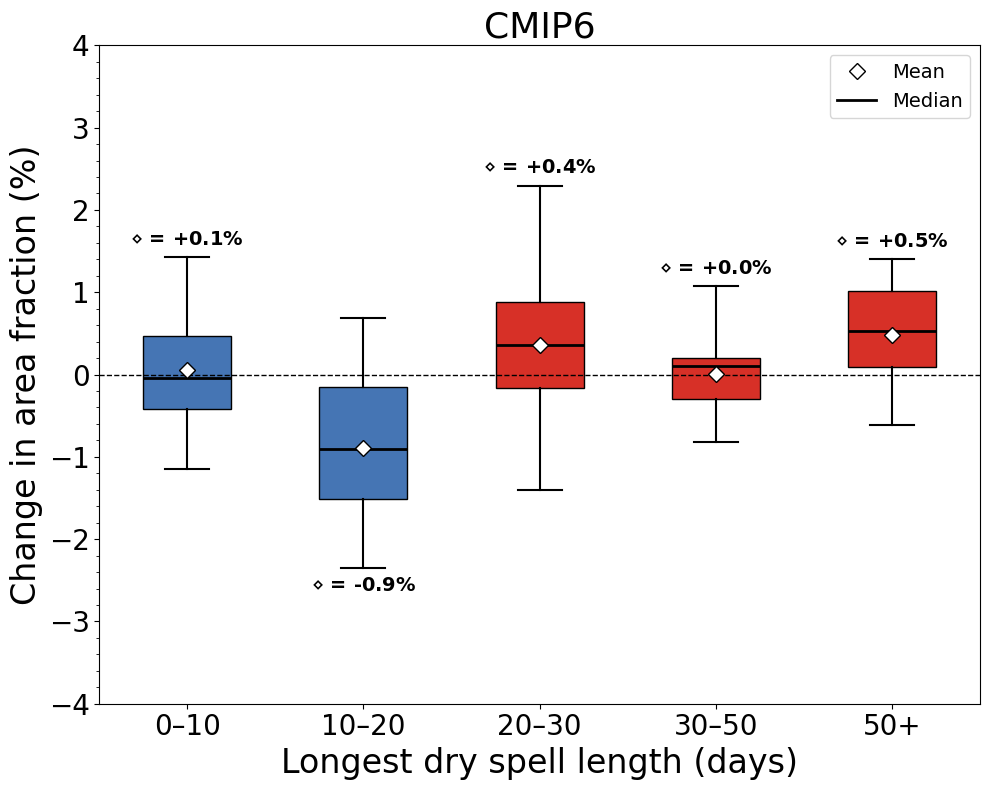

In [5]:
# ── plot: one box per class over the models (equal weight per model) ──
model_vals = change.drop(index='CMIP6 mean')[bin_labels].values    # (n_models, n_bins)
data_by_bin = [model_vals[:, i] for i in range(len(bin_labels))]

fig, ax = plt.subplots(figsize=(10, 8))
x = np.arange(len(bin_labels))
bp = ax.boxplot(
    data_by_bin,
    positions=x,
    widths=0.5,
    whis=(0, 100),            # whiskers extend to min/max model
    patch_artist=True,
    showmeans=True,
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=8),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
)

# Colour each box based on whether the median is positive or negative
for patch, data in zip(bp['boxes'], data_by_bin):
    patch.set_facecolor('#d73027' if np.median(data) >= 0 else '#4575b4')

# Annotate the CMIP6 mean (diamond) beyond the end of the whisker
for i, data in enumerate(data_by_bin):
    mean_val = np.mean(data)
    if mean_val >= 0:
        ypos, va, dy = np.max(data), 'bottom', 6
    else:
        ypos, va, dy = np.min(data), 'top', -6
    ax.annotate(f'$\\diamond$ = {mean_val:+.1f}%', xy=(i, ypos), xytext=(0, dy), textcoords='offset points',
                ha='center', va=va, fontsize=14, fontweight='bold')

ax.axhline(0, color='black', linewidth=1.0, linestyle='--')
ax.set_xticks(x)
ax.set_xticklabels(bin_labels, fontsize=20)
ax.set_xlabel('Longest dry spell length (days)', fontsize=24)
ax.set_ylabel('Change in area fraction (%)', fontsize=24)
ax.tick_params(axis='both', labelsize=20)
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
if YLIM is None:
    lim = np.ceil(1.25 * np.abs(model_vals).max() + 0.5)
    ax.set_ylim(-lim, lim)
else:
    ax.set_ylim(*YLIM)
    if model_vals.min() < YLIM[0] or model_vals.max() > YLIM[1]:
        print(f'WARNING: model values span {model_vals.min():.2f} to {model_vals.max():.2f}, outside YLIM {YLIM}')
ax.set_title('CMIP6', fontsize=26)

legend_elements = [
    Line2D([0], [0], marker='D', color='w', markerfacecolor='white',
           markeredgecolor='black', markersize=8, label='Mean'),
    Line2D([0], [0], color='black', linewidth=2, label='Median'),
]
ax.legend(handles=legend_elements, fontsize=14, loc='upper right')

plt.tight_layout()
os.makedirs(os.path.dirname(OUT_FIG), exist_ok=True)
plt.savefig(OUT_FIG, format='pdf', bbox_inches='tight')
plt.show()